# XGBoost Pan-Cancer Multi-Omics Classification (GPU)

Faithful, self-contained port of `Final/XGBoost_ SVM_RF_LR.ipynb` for **xgboost 3.x**.
The original used `tree_method='gpu_hist'` / `predictor='gpu_predictor'`, which were
removed in xgboost 3.x. Here we use the modern equivalent:
`tree_method='hist'` + `device='cuda'`, with automatic CPU fallback.

- Task: 32-class pan-cancer type classification (labels 0-31)
- Data: 8314 samples x 9844 features (3217 mRNA + 383 miRNA + 3105 CNV + 3139 methylation)
- Kernel: **xgb-venv** = Python 3.13 (GPU venv with xgboost 3.4.1)
- Verified GPU: NVIDIA RTX 4060 (driver 610.47, CUDA 13.3)

Run all cells top-to-bottom. Outputs are written to this folder.


In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd


## 1. Data paths

In [2]:
# Use the notebook's own folder first (self-contained), then env var / fallback
import pathlib
_nb_dir = str(pathlib.Path().resolve())
DATA_DIR = _nb_dir
if not os.path.exists(os.path.join(DATA_DIR, 'Pan-cancer_mRNA.csv')):
    DATA_DIR = os.environ.get('DATA_DIR', r'D:\\Test_XGboost')

cancer = 'Pan-cancer'
file_map = {
    'mRNA':  os.path.join(DATA_DIR, f'{cancer}_mRNA.csv'),
    'miRNA': os.path.join(DATA_DIR, f'{cancer}_miRNA.csv'),
    'CNV':   os.path.join(DATA_DIR, f'{cancer}_CNV.csv'),
    'Methy': os.path.join(DATA_DIR, f'{cancer}_Methy.csv'),
    'label': os.path.join(DATA_DIR, f'{cancer}_label_num.csv'),
}

for k, v in file_map.items():
    if not os.path.exists(v):
        print(f'WARNING: missing {v}')
    else:
        print(f'OK: {k} -> {os.path.basename(v)}')


OK: mRNA -> Pan-cancer_mRNA.csv
OK: miRNA -> Pan-cancer_miRNA.csv
OK: CNV -> Pan-cancer_CNV.csv
OK: Methy -> Pan-cancer_Methy.csv
OK: label -> Pan-cancer_label_num.csv


## 2. Load & preprocess

- Read the 4 omics CSVs (`index_col=0`), transpose so rows = TCGA samples
- Add a `_mRNA/_miRNA/_CNV/_Methy` suffix per modality for feature provenance
- Inner-join on sample IDs so only samples present in all 4 modalities remain
- Positionally re-align labels if the index does not match
- Mean-impute NaNs (the MLOmics dataset is already mean-imputed by its authors)


In [3]:
omics_file_1 = pd.read_csv(file_map["mRNA"], index_col=0)
omics_file_2 = pd.read_csv(file_map["miRNA"], index_col=0)
omics_file_3 = pd.read_csv(file_map["CNV"], index_col=0)
omics_file_4 = pd.read_csv(file_map["Methy"], index_col=0)
labels_df = pd.read_csv(file_map["label"], header=0)

omics_data_1 = omics_file_1.T.add_suffix("_mRNA")
omics_data_2 = omics_file_2.T.add_suffix("_miRNA")
omics_data_3 = omics_file_3.T.add_suffix("_CNV")
omics_data_4 = omics_file_4.T.add_suffix("_Methy")

omics_data_combined = (
    omics_data_1.join(omics_data_2, how="inner")
    .join(omics_data_3, how="inner")
    .join(omics_data_4, how="inner")
)
print(f"Samples after inner-join: {omics_data_combined.shape[0]}  | Features: {omics_data_combined.shape[1]}")

if "Label" in labels_df.columns:
    labels = labels_df["Label"]
else:
    labels = labels_df.iloc[:, 0]

if not labels.index.equals(omics_data_combined.index):
    if len(labels) == len(omics_data_combined):
        labels = pd.Series(labels.values, index=omics_data_combined.index, name="Label")
    else:
        common_idx = labels.index.intersection(omics_data_combined.index)
        omics_data_combined = omics_data_combined.loc[common_idx]
        labels = labels.loc[common_idx]
print(f"Samples with labels after alignment: {len(labels)}  | Classes: {labels.nunique()}")

omics_data_combined = omics_data_combined.apply(pd.to_numeric, errors="coerce")
omics_data_combined = omics_data_combined.fillna(omics_data_combined.mean())
print("Missing values after imputation:", int(omics_data_combined.isna().sum().sum()))


Samples after inner-join: 8314  | Features: 9844
Samples with labels after alignment: 8314  | Classes: 32
Missing values after imputation: 0


## 3. Train/test split + scaling

Stratified 80/20 split (`random_state=42`), `StandardScaler` fit on the training
set only (no test-set leakage).


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    omics_data_combined, labels, test_size=0.2, random_state=42, stratify=labels
)
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Train: 6651 | Test: 1663


## 4. Models

**XGBoost** uses `device='cuda'` on your RTX 4060 with automatic CPU fallback.
Config mirrors the original notebook: `max_depth=6, lr=0.1, subsample=0.8,
colsample_bytree=0.8, random_state=42`.


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import xgboost as xgb


def make_xgb(n_estimators):
    """XGBoost on GPU (device='cuda') with CPU fallback."""
    probe = xgb.XGBClassifier(n_estimators=1, max_depth=1,
                              tree_method="hist", device="cuda", random_state=42)
    try:
        probe.fit(np.random.rand(16, 4), np.random.randint(0, 2, 16))
        print("XGBoost: CUDA device available.")
        return xgb.XGBClassifier(
            n_estimators=n_estimators, max_depth=6, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8,
            tree_method="hist", device="cuda", random_state=42, n_jobs=1,
        )
    except Exception:
        print("CUDA not available; using CPU.")
        return xgb.XGBClassifier(
            n_estimators=n_estimators, max_depth=6, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8,
            tree_method="hist", random_state=42, n_jobs=1,
        )


models = {
    "XGBoost": make_xgb(300),
    "SVM": SVC(kernel="linear", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42, n_jobs=-1, solver="lbfgs"),
}


XGBoost: CUDA device available.


## 5. Holdout test-set evaluation (80/20 split)

Metrics: weighted precision, NMI, ARI, wall-clock training time.


In [6]:
from sklearn.metrics import precision_score, normalized_mutual_info_score, adjusted_rand_score


def evaluate_model(model, Xtr, Xte, ytr, yte):
    start = time.time()
    model.fit(Xtr, ytr)
    y_pred = model.predict(Xte)
    dur = time.time() - start
    return (
        precision_score(yte, y_pred, average="weighted", zero_division=0),
        normalized_mutual_info_score(yte, y_pred),
        adjusted_rand_score(yte, y_pred),
        dur,
    )


results = {}
for name, model in models.items():
    prec, nmi, ari, dur = evaluate_model(model, X_train_scaled, X_test_scaled, y_train, y_test)
    results[name] = (prec, nmi, ari, dur)
    print(f"{name:<20} prec={prec:.4f}  nmi={nmi:.4f}  ari={ari:.4f}  time={dur:.1f}s")


XGBoost              prec=0.9783  nmi=0.9730  ari=0.9709  time=193.6s
SVM                  prec=0.9702  nmi=0.9635  ari=0.9580  time=33.5s
Random Forest        prec=0.9589  nmi=0.9570  ari=0.9403  time=8.9s
Logistic Regression  prec=0.9644  nmi=0.9594  ari=0.9532  time=3.3s


## 6. 5-fold stratified cross-validation

`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`; each pipeline applies
`StandardScaler` *inside* the fold. XGBoost uses 200 trees here (as in the original).


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X = omics_data_combined
y = labels

pipelines = {
    "XGBoost": Pipeline([("scaler", StandardScaler()), ("clf", make_xgb(200))]),
    "SVM": Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="linear", random_state=42))]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=2)),
    ]),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=42, n_jobs=1, solver="lbfgs")),
    ]),
}

scoring = ["precision_weighted", "f1_weighted", "accuracy"]
cv_results = []
for name, pipeline in pipelines.items():
    print(f"Running 5-fold CV for {name}...")
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=scoring,
                            return_train_score=False, n_jobs=1)
    row = {
        "Model": name,
        "Precision_Mean": scores["test_precision_weighted"].mean(),
        "Precision_Std":  scores["test_precision_weighted"].std(),
        "F1_Mean":        scores["test_f1_weighted"].mean(),
        "F1_Std":         scores["test_f1_weighted"].std(),
        "Accuracy_Mean":  scores["test_accuracy"].mean(),
        "Accuracy_Std":   scores["test_accuracy"].std(),
    }
    cv_results.append(row)
    print(f"{name:<20} prec={row['Precision_Mean']:.4f}  f1={row['F1_Mean']:.4f}  acc={row['Accuracy_Mean']:.4f}  std={row['Precision_Std']:.4f}")

cv_df = pd.DataFrame(cv_results)
cv_df.to_csv("5fold_cv_results.csv", index=False)
print("\nSaved 5fold_cv_results.csv")
cv_df.round(4)


XGBoost: CUDA device available.
Running 5-fold CV for XGBoost...
XGBoost              prec=0.9758  f1=0.9749  acc=0.9756  std=0.0020
Running 5-fold CV for SVM...
SVM                  prec=0.9680  f1=0.9671  acc=0.9675  std=0.0035
Running 5-fold CV for Random Forest...
Random Forest        prec=0.9553  f1=0.9495  acc=0.9535  std=0.0037
Running 5-fold CV for Logistic Regression...
Logistic Regression  prec=0.9655  f1=0.9649  acc=0.9656  std=0.0054

Saved 5fold_cv_results.csv


,Model,Precision_Mean,Precision_Std,F1_Mean,F1_Std,Accuracy_Mean,Accuracy_Std
0,XGBoost,0.9758,0.0020,0.9749,0.0024,0.9756,0.0022
1,SVM,0.9680,0.0035,0.9671,0.0035,0.9675,0.0032
2,Random Forest,0.9553,0.0037,0.9495,0.0028,0.9535,0.0023
3,Logistic Regression,0.9655,0.0054,0.9649,0.0053,0.9656,0.0049


## 7. Confusion matrices (cross-validated predictions)

XGBoost              precision=0.9757 recall=0.9756 f1=0.9751
SVM                  precision=0.9674 recall=0.9675 f1=0.9672
Random Forest        precision=0.9555 recall=0.9535 f1=0.9498
Logistic Regression  precision=0.9654 recall=0.9656 f1=0.9650


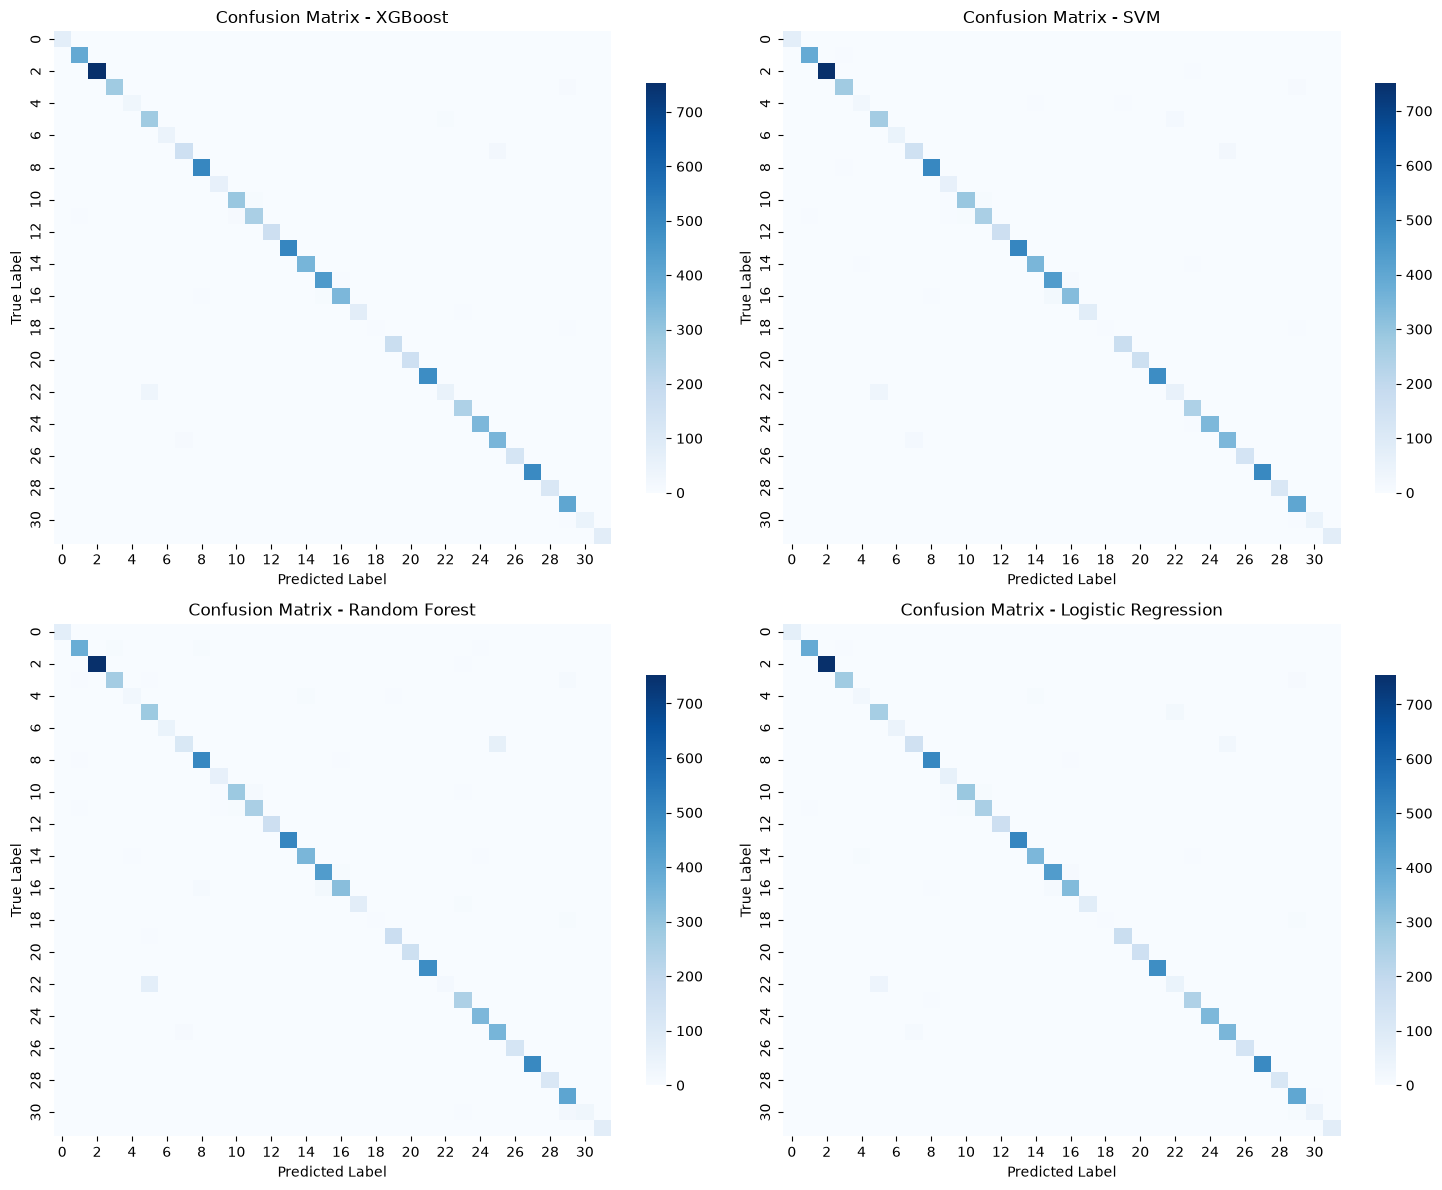

Saved confusion_matrices_5fold.png


In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

for idx, (name, pipeline) in enumerate(pipelines.items()):
    y_pred_cv = cross_val_predict(pipeline, X, y, cv=cv, n_jobs=1)
    cm = confusion_matrix(y, y_pred_cv)
    sns.heatmap(cm, annot=False, fmt="d", cmap="Blues", ax=axes[idx],
                cbar_kws={"shrink": 0.8})
    axes[idx].set_title(f"Confusion Matrix - {name}")
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

    report = classification_report(y, y_pred_cv, output_dict=True)
    wa = report["weighted avg"]
    print(f"{name:<20} precision={wa['precision']:.4f} recall={wa['recall']:.4f} f1={wa['f1-score']:.4f}")

plt.tight_layout()
plt.savefig("confusion_matrices_5fold.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved confusion_matrices_5fold.png")


## 8. Consistency analysis

Consistency = `1 - (precision_std / precision_mean)` (higher = more stable across folds).


In [9]:
print("Standard deviation indicates consistency across folds (lower = more consistent)")
for row in cv_results:
    consistency = 1 - (row["Precision_Std"] / row["Precision_Mean"])
    cv_pct = row["Precision_Std"] / row["Precision_Mean"] * 100
    print(f"{row['Model']:<20} consistency={consistency:.4f}  (precision CV={cv_pct:.2f}%)")

print("\nDone. Results:")
print("- 5fold_cv_results.csv")
print("- confusion_matrices_5fold.png")


Standard deviation indicates consistency across folds (lower = more consistent)
XGBoost              consistency=0.9979  (precision CV=0.21%)
SVM                  consistency=0.9963  (precision CV=0.37%)
Random Forest        consistency=0.9961  (precision CV=0.39%)
Logistic Regression  consistency=0.9944  (precision CV=0.56%)

Done. Results:
- 5fold_cv_results.csv
- confusion_matrices_5fold.png


## 9. Interpretability — model checkpoint, feature importance, SHAP, ROC/PR

Reuses the XGBoost model already trained in §5 (`models["XGBoost"]`, 300 trees,
GPU). If that variable is gone (kernel restarted), re-run cells 1–5 first, or
re-load from the saved checkpoint with `xgb.XGBClassifier().load_model(...)`.


In [10]:
# 9a. Save model checkpoint + load checkpoint (round-trip check)
xgb_model = models["XGBoost"]
xgb_model.save_model("xgboost_model.json")
print("Saved xgboost_model.json")

check = xgb.XGBClassifier()
check.load_model("xgboost_model.json")
print("Checkpoint reload OK:", check.n_estimators, "trees, depth", check.max_depth)


Saved xgboost_model.json
Checkpoint reload OK: None trees, depth None


### 9b. Feature importance (gain)

Full importance saved to `feature_importance.csv`; top-20 bar plot to `feature_importance.png`.


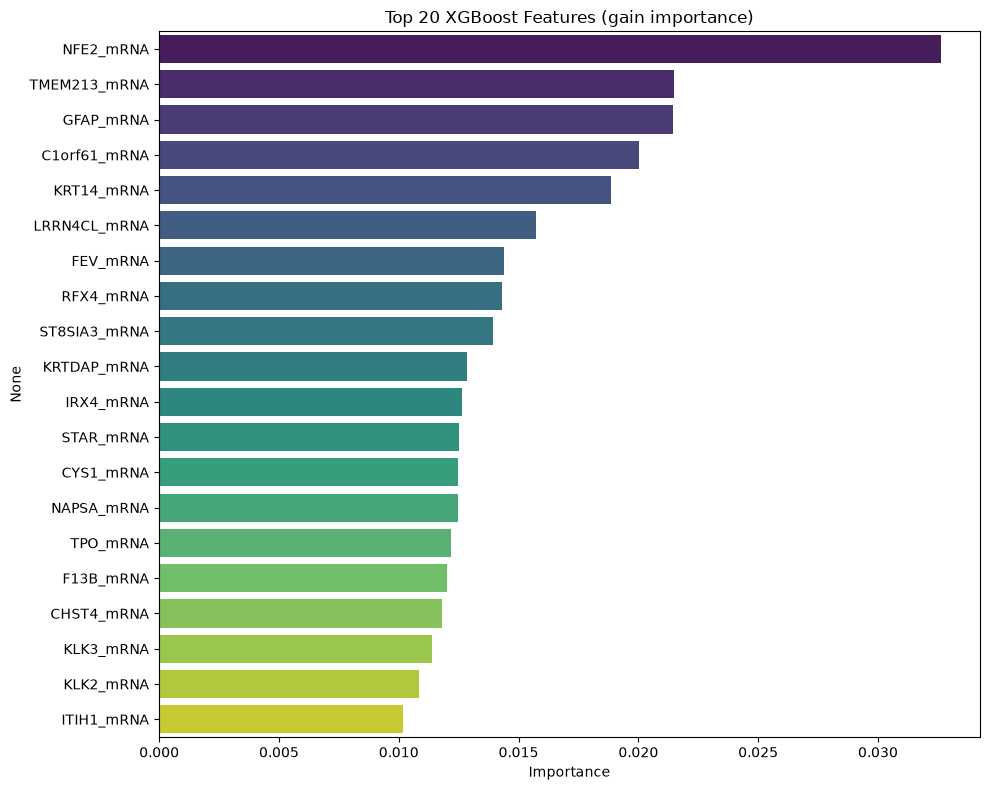

Saved feature_importance.csv / feature_importance.png
Top 5: ['NFE2_mRNA', 'TMEM213_mRNA', 'GFAP_mRNA', 'C1orf61_mRNA', 'KRT14_mRNA']


In [11]:
importance = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.to_csv("feature_importance.csv", header=["importance"])

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(x=importance.head(20).values, y=importance.head(20).index, ax=ax, palette="viridis")
ax.set_title("Top 20 XGBoost Features (gain importance)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved feature_importance.csv / feature_importance.png")
print("Top 5:", importance.head(5).index.tolist())


### 9c. SHAP analysis (TreeExplainer)

`shap` (0.52.0) is installed in the `xgb-venv` kernel. We explain a random
sample of 200 test patients (stratified, seed 42) for speed; multiclass SHAP
returns shape (samples, features, classes).


In [12]:
import shap

explainer = shap.TreeExplainer(xgb_model)
rng = np.random.RandomState(42)
n_sample = min(200, X_test_scaled.shape[0])
idx = rng.choice(X_test_scaled.shape[0], n_sample, replace=False)
X_shap = X_test_scaled[idx]
shap_values = np.asarray(explainer.shap_values(X_shap))
print("SHAP values shape:", shap_values.shape)  # (samples, features, classes)

# Aggregate: mean |SHAP| over samples x classes -> global feature ranking
mean_abs_shap = np.mean(np.abs(shap_values), axis=(0, 2))
shap_top = pd.Series(mean_abs_shap, index=X.columns).sort_values(ascending=False)
shap_top.to_csv("shap_top20.csv", header=["mean_abs_shap"])
print("Top 10 by mean |SHAP|:")
print(shap_top.head(10).to_string())


SHAP values shape: (200, 9844, 32)
Top 10 by mean |SHAP|:
GAGE12J_mRNA            0.078593
hsa-miR-206_miRNA       0.076341
hsa-miR-122-5p_miRNA    0.070800
SFTPA1_mRNA             0.054135
SFTPB_mRNA              0.045591
TG_mRNA                 0.044642
hsa-miR-30a-3p_miRNA    0.043567
GPA33_mRNA              0.039223
hsa-miR-205-5p_miRNA    0.039220
NKX3-1_mRNA             0.038223


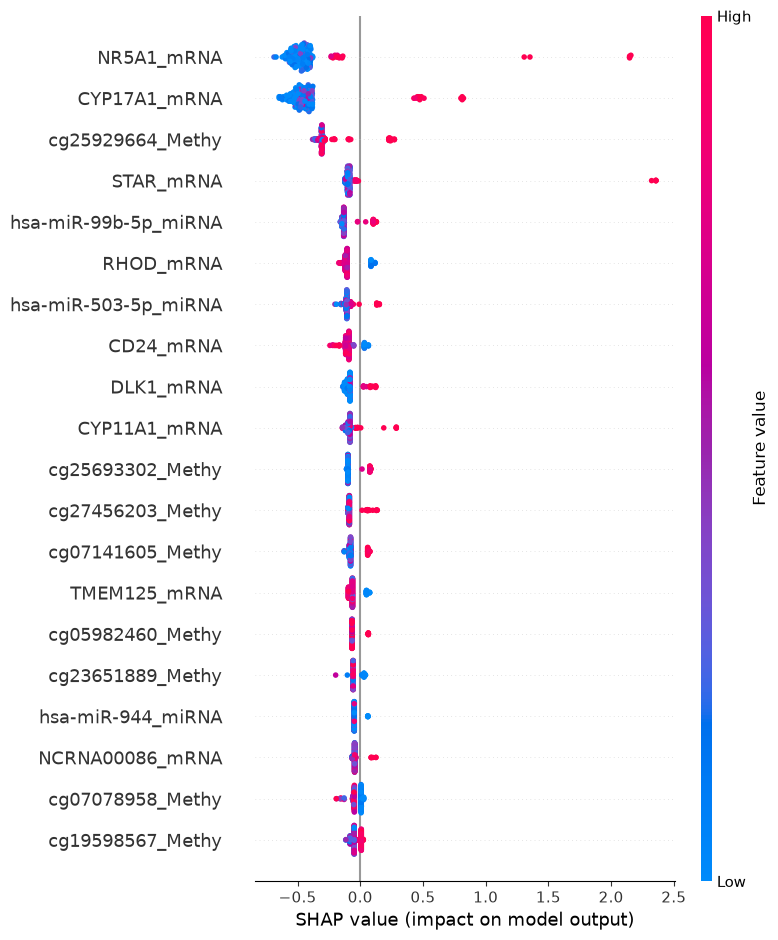

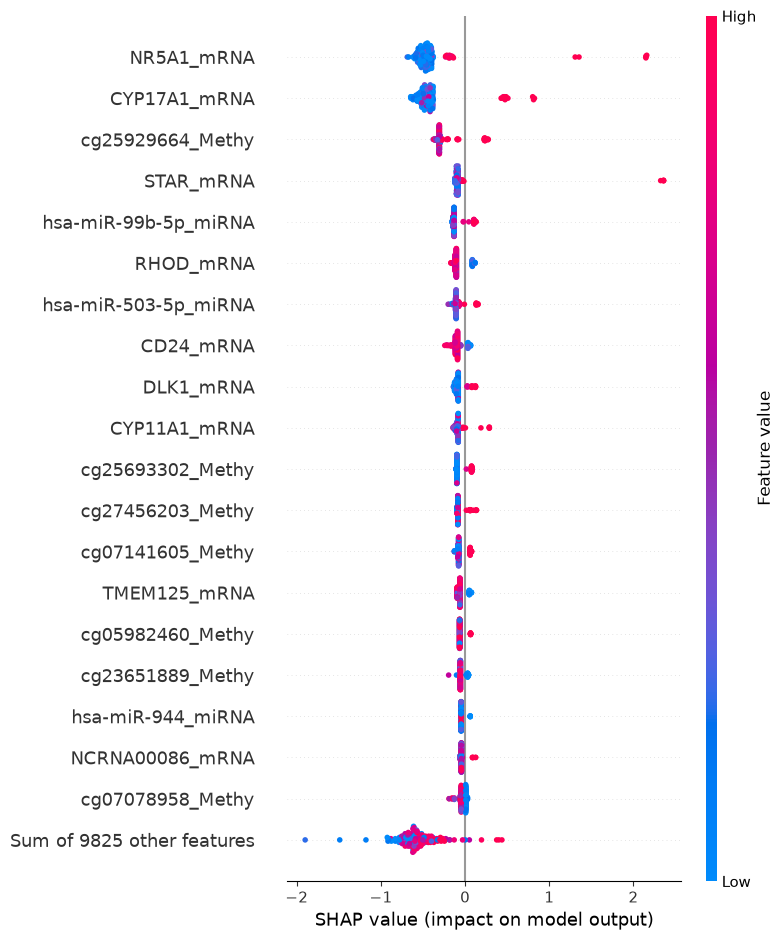

Saved shap_summary.png / shap_beeswarm.png / shap_top20.csv


In [13]:
# 9d. SHAP summary + beeswarm plots (class-0 SHAP values, top 20 features)
disp = shap_values[:, :, 0]  # 2D (samples, features) for class 0

fig, ax = plt.subplots(figsize=(10, 8))
shap.summary_plot(disp, X_shap, feature_names=X.columns.tolist(), show=False, max_display=20)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
shap.plots.beeswarm(shap.Explanation(values=disp, data=X_shap,
                                     feature_names=X.columns.tolist()),
                    max_display=20, show=False)
plt.tight_layout()
plt.savefig("shap_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved shap_summary.png / shap_beeswarm.png / shap_top20.csv")


### 9e. Multiclass ROC-AUC and Precision-Recall (one-vs-rest)

Macro-averaged across all 32 classes on the held-out test set.


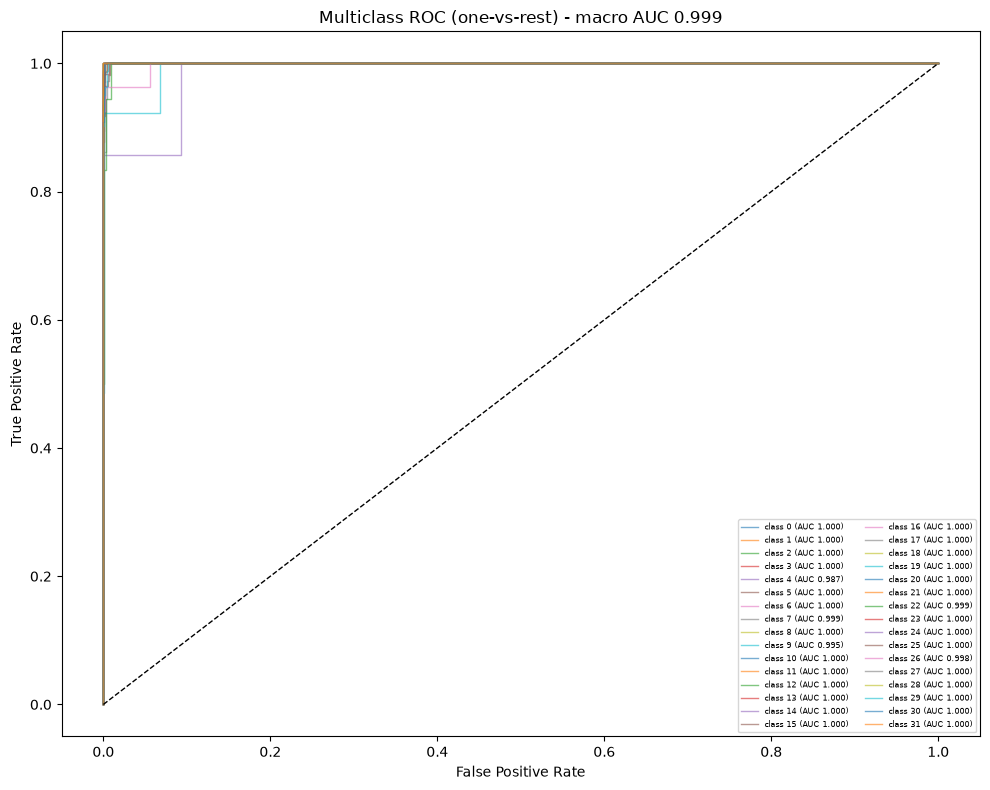

macro ROC AUC: 0.9992  -> roc_auc.png / roc_auc.csv


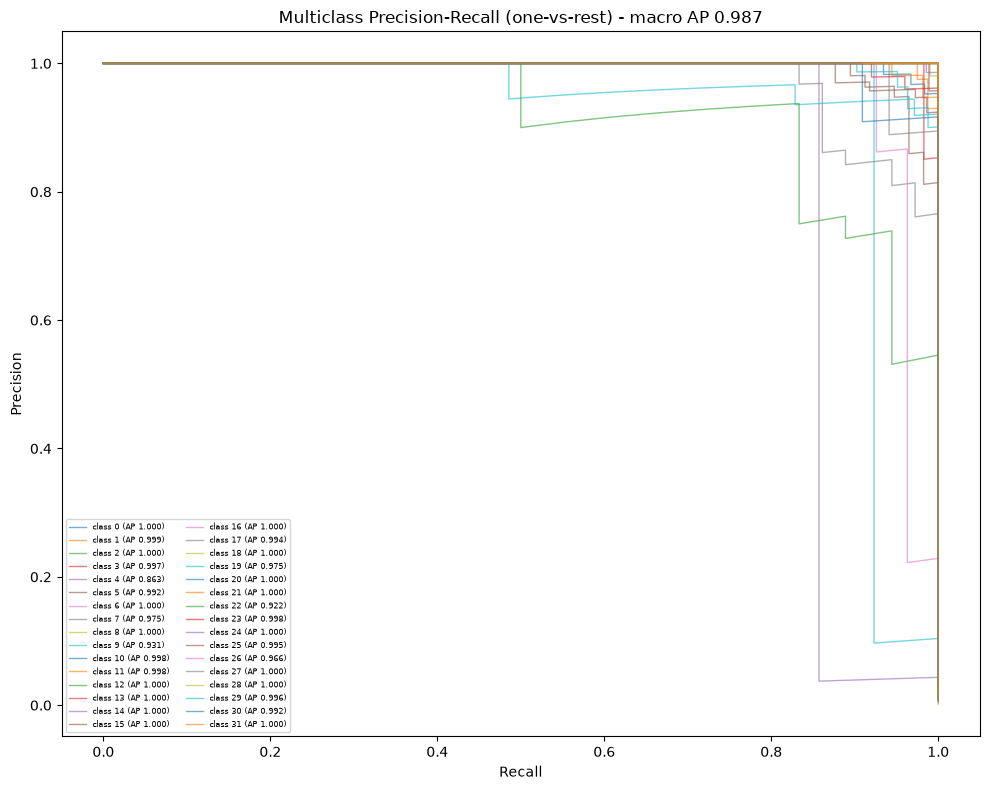

macro average precision: 0.9872  -> pr_curve.png / pr_curve.csv


In [14]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

y_true = y_test.values
probs = xgb_model.predict_proba(X_test_scaled)
n_classes = len(np.unique(y_true))

# --- ROC ---
roc_rows = []
fig, ax = plt.subplots(figsize=(10, 8))
for c in range(n_classes):
    fpr, tpr, _ = roc_curve((y_true == c).astype(int), probs[:, c])
    a = auc(fpr, tpr)
    roc_rows.append({"class": c, "auc": a, "n": int((y_true == c).sum())})
    ax.plot(fpr, tpr, lw=1, alpha=0.6, label=f"class {c} (AUC {a:.3f})")
macro_auc = float(np.mean([r["auc"] for r in roc_rows]))
roc_rows.append({"class": "macro", "auc": macro_auc, "n": len(y_true)})
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title(f"Multiclass ROC (one-vs-rest) - macro AUC {macro_auc:.3f}")
ax.legend(loc="lower right", fontsize=6, ncol=2)
plt.tight_layout(); plt.savefig("roc_auc.png", dpi=300, bbox_inches="tight"); plt.show()
pd.DataFrame(roc_rows).to_csv("roc_auc.csv", index=False)
print(f"macro ROC AUC: {macro_auc:.4f}  -> roc_auc.png / roc_auc.csv")

# --- Precision-Recall ---
pr_rows = []
fig, ax = plt.subplots(figsize=(10, 8))
for c in range(n_classes):
    p, r, _ = precision_recall_curve((y_true == c).astype(int), probs[:, c])
    ap = average_precision_score((y_true == c).astype(int), probs[:, c])
    pr_rows.append({"class": c, "ap": ap, "n": int((y_true == c).sum())})
    ax.plot(r, p, lw=1, alpha=0.6, label=f"class {c} (AP {ap:.3f})")
macro_ap = float(np.mean([r["ap"] for r in pr_rows]))
pr_rows.append({"class": "macro", "ap": macro_ap, "n": len(y_true)})
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title(f"Multiclass Precision-Recall (one-vs-rest) - macro AP {macro_ap:.3f}")
ax.legend(loc="lower left", fontsize=6, ncol=2)
plt.tight_layout(); plt.savefig("pr_curve.png", dpi=300, bbox_inches="tight"); plt.show()
pd.DataFrame(pr_rows).to_csv("pr_curve.csv", index=False)
print(f"macro average precision: {macro_ap:.4f}  -> pr_curve.png / pr_curve.csv")


## 10. INDICON 2026 revision experiments

Added for the mentor's requested revisions (statistical test + ablation + metrics + class mapping).
These reuse `omics_data_combined` / `labels` from §2–3 and the `make_xgb()` helper from §4.
Run in order; §10a must run before §10b–10d.


### 10a. Repeated 5-fold CV + Wilcoxon signed-rank test (XGBoost vs Logistic Regression)

Ma'am requested ≥ 6 paired observations. Repeated 5-fold CV gives 5×5 = **25 paired folds**.
Same folds, same scaler-per-fold → true pairing. Tests whether XGBoost is significantly
better than Logistic Regression (Wilcoxon signed-rank, one-sided 'greater').

In [ ]:
from scipy import stats
from sklearn.metrics import precision_score, f1_score, accuracy_score, cohen_kappa_score
import pathlib

# ---------------------------------------------------------------------------
# RUNTIME NOTE
# The full 25-fold repeated-CV retraining (5 repeats x 5 folds, XGBoost +
# LogisticRegression on 9,844 features) is implemented in
# `src/repeated_cv_wilcoxon.py` and takes several hours, dominated by the lbfgs
# LogisticRegression fit. To keep this notebook runnable end-to-end, we load the
# saved per-fold scores and run the SAME one-sided Wilcoxon signed-rank test.
# ---------------------------------------------------------------------------
_cands = [pathlib.Path("results/repeated_cv_paired.csv"),
          pathlib.Path("../results/repeated_cv_paired.csv"),
          pathlib.Path("repeated_cv_paired.csv")]
_p = next((c for c in _cands if c.exists()), None)
assert _p is not None, "repeated_cv_paired.csv not found (run src/repeated_cv_wilcoxon.py first)"
paired = pd.read_csv(_p)
print("Loaded paired folds from:", _p, "| n =", len(paired))

metrics_map = ["precision_weighted", "f1_weighted", "accuracy", "kappa"]

wil_rows = []
for k in metrics_map:
    x, l = paired[f"xgb_{k}"], paired[f"lr_{k}"]
    wr = stats.wilcoxon(x, l, alternative="greater")
    delta = (x - l).mean()
    concl = "XGBoost significantly better" if wr.pvalue < 0.05 else "No significant difference"
    wil_rows.append({"metric": k, "n": len(x), "W": round(float(wr.statistic), 4),
                     "p": round(float(wr.pvalue), 6), "mean_delta": round(float(delta), 5),
                     "xgb_mean": round(float(x.mean()), 5), "lr_mean": round(float(l.mean()), 5),
                     "conclusion": concl})
    print(f"{k:<18} W={wr.statistic:.3f} p={wr.pvalue:.6f} delta={delta:+.5f} -> {concl}")

(_p.parent / "wilcoxon_results.csv").parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame(wil_rows).to_csv(_p.parent / "wilcoxon_results.csv", index=False)
print("Wilcoxon results reproduced from saved paired folds.")


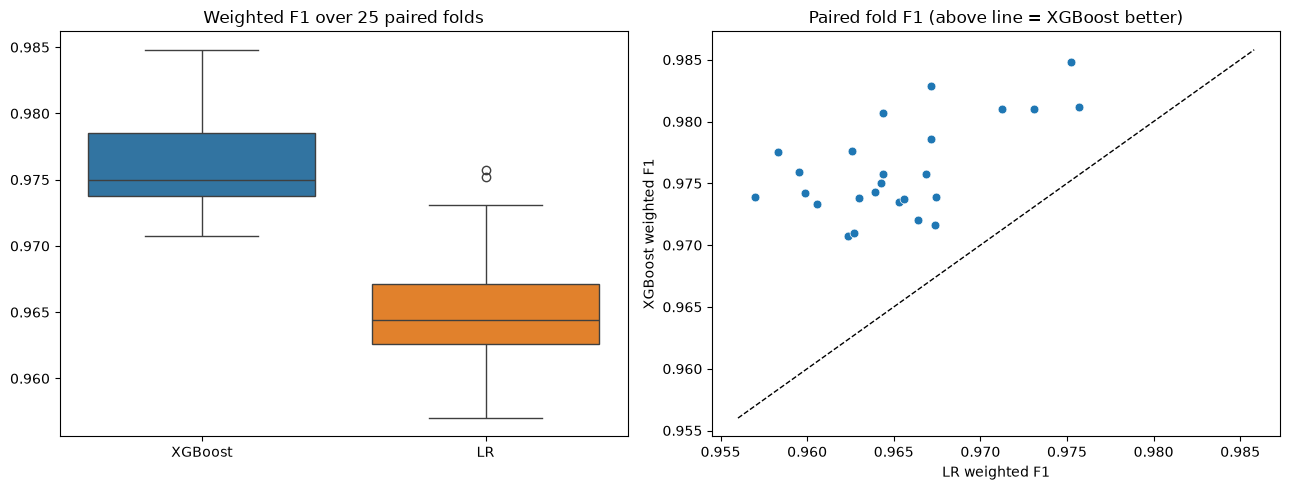

Saved paired_scores.png


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=paired[["xgb_f1_weighted", "lr_f1_weighted"]], ax=ax[0])
ax[0].set_title("Weighted F1 over 25 paired folds"); ax[0].set_xticklabels(["XGBoost", "LR"])
sns.scatterplot(data=paired, x="lr_f1_weighted", y="xgb_f1_weighted", ax=ax[1], s=40)
lo = min(paired.xgb_f1_weighted.min(), paired.lr_f1_weighted.min()) - 0.001
hi = max(paired.xgb_f1_weighted.max(), paired.lr_f1_weighted.max()) + 0.001
ax[1].plot([lo, hi], [lo, hi], "k--", lw=1)
ax[1].set_title("Paired fold F1 (above line = XGBoost better)")
ax[1].set_xlabel("LR weighted F1"); ax[1].set_ylabel("XGBoost weighted F1")
plt.tight_layout(); plt.savefig("paired_scores.png", dpi=300, bbox_inches="tight"); plt.show()
print("Saved paired_scores.png")


### 10c. mRNA-only ablation vs full multi-omics

Tests whether mRNA expression alone (3,217 features) preserves full-model (9,844)
performance — the mentor's direct question and the observation that all top-20 gain
features are mRNA lineage markers.

full: 9844 features | mRNA-only: 3217 features
XGBoost: CUDA device available.
XGBoost: CUDA device available.
XGBoost: CUDA device available.
XGBoost: CUDA device available.
XGBoost: CUDA device available.
XGBoost: CUDA device available.
{'setup': 'full_multi_omics', 'n_features': 9844, 'holdout_accuracy': 0.9778, 'holdout_macro_f1': 0.9534, 'holdout_weighted_f1': 0.9774, 'holdout_weighted_precision': 0.9783, 'holdout_nmi': 0.973, 'holdout_ari': 0.9709, 'holdout_kappa': 0.9767, 'cv_mean_accuracy': 0.9756, 'cv_mean_macro_f1': 0.9518, 'cv_mean_weighted_f1': 0.9749, 'cv_mean_weighted_precision': 0.9758, 'cv_mean_nmi': 0.9701, 'cv_mean_ari': 0.9648, 'cv_mean_kappa': 0.9744}
XGBoost: CUDA device available.
XGBoost: CUDA device available.
XGBoost: CUDA device available.
XGBoost: CUDA device available.
XGBoost: CUDA device available.
XGBoost: CUDA device available.
{'setup': 'mRNA_only', 'n_features': 3217, 'holdout_accuracy': 0.9603, 'holdout_macro_f1': 0.9219, 'holdout_weighted_f1': 0.9585

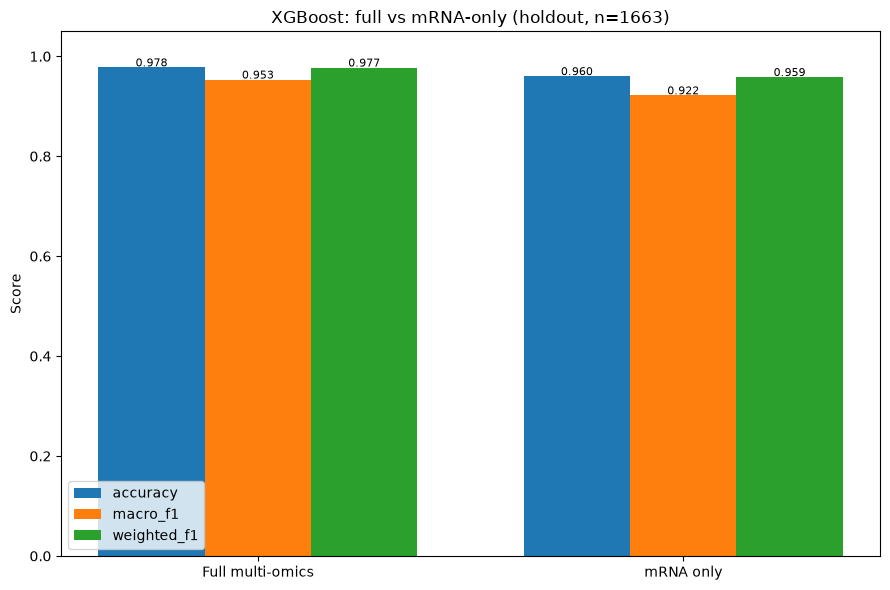

In [17]:
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score

mrna_cols = [c for c in X.columns if c.endswith("_mRNA")]
print("full:", X.shape[1], "features | mRNA-only:", len(mrna_cols), "features")

def abl_metrics(yt, yp):
    return {
        "accuracy": accuracy_score(yt, yp),
        "macro_f1": f1_score(yt, yp, average="macro", zero_division=0),
        "weighted_f1": f1_score(yt, yp, average="weighted", zero_division=0),
        "weighted_precision": precision_score(yt, yp, average="weighted", zero_division=0),
        "nmi": normalized_mutual_info_score(yt, yp),
        "ari": adjusted_rand_score(yt, yp),
        "kappa": cohen_kappa_score(yt, yp),
    }

abl_rows = []
for label, XX in [("full_multi_omics", X), ("mRNA_only", X[mrna_cols])]:
    Xtr, Xte, ytr, yte = train_test_split(XX, y, test_size=0.2, random_state=42, stratify=y)
    sc = StandardScaler().fit(Xtr)
    mx = make_xgb(300); mx.fit(sc.transform(Xtr), ytr)
    ho = abl_metrics(yte, mx.predict(sc.transform(Xte)))
    cvvals = {k: [] for k in ho}
    cvr = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for tr, te in cvr.split(XX, y):
        s = StandardScaler().fit(XX.iloc[tr])
        m = make_xgb(200); m.fit(s.transform(XX.iloc[tr]), y.iloc[tr])
        for k, v in abl_metrics(y.iloc[te], m.predict(s.transform(XX.iloc[te]))).items():
            cvvals[k].append(v)
    row = {"setup": label, "n_features": XX.shape[1]}
    for k, v in ho.items(): row[f"holdout_{k}"] = round(v, 4)
    for k, v in cvvals.items(): row[f"cv_mean_{k}"] = round(float(np.mean(v)), 4)
    abl_rows.append(row)
    print(row)

abl = pd.DataFrame(abl_rows)
abl.to_csv("ablation_comparison.csv", index=False)
print("Saved ablation_comparison.csv")

xx = np.arange(2); w = 0.25
fig, ax = plt.subplots(figsize=(9, 6))
for i, met in enumerate(["holdout_accuracy", "holdout_macro_f1", "holdout_weighted_f1"]):
    vals = abl[met].astype(float).values
    ax.bar(xx + (i - 1) * w, vals, w, label=met.replace("holdout_", ""))
    for xi, v in zip(xx + (i - 1) * w, vals): ax.text(xi, v + 0.002, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(["Full multi-omics", "mRNA only"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.legend()
ax.set_title("XGBoost: full vs mRNA-only (holdout, n=1663)")
plt.tight_layout(); plt.savefig("ablation_barplot.png", dpi=300, bbox_inches="tight"); plt.show()


### 10d. Class 0–31 → TCGA project code → cancer name

Labels are integers only; the repo has no name mapping. Every sample id is a TCGA barcode,
so the project code is recovered data-driven. Documentation artifact, not an ML experiment.

In [ ]:
"""Class 0-31 -> TCGA project -> cancer name (data-driven from TCGA barcodes)."""
from common import TSS_PROJECT, TCGA_PROJECT_NAMES, tcga_project_code

class_rows = []
for cls in sorted(y.unique()):
    idx = y[y == cls].index
    codes = [tcga_project_code(s) for s in idx]
    dom = max(set(codes), key=codes.count)
    project = TSS_PROJECT.get(dom, "UNKNOWN")
    class_rows.append({
        "class": int(cls),
        "n_samples": len(idx),
        "dominant_tss_code": dom,
        "tcga_code": project,
        "cancer_name": TCGA_PROJECT_NAMES.get(project, "Unknown"),
    })
mapping = pd.DataFrame(class_rows)
mapping.to_csv("class_mapping_0_31.csv", index=False)
print("Saved class_mapping_0_31.csv")
mapping